# Autoencoders and VAEs

Everything so far was *discriminative*: input in, label out. **Generative** models learn the data itself, so they can produce new samples.

This notebook:

1. **Autoencoder (AE)**: compress an image to a small code, then reconstruct it
2. Why a plain AE is a poor *generator* (its latent space has holes)
3. **Variational Autoencoder (VAE)**: force the latent space to be smooth so sampling works
4. The pieces: **reparameterization trick**, **ELBO loss** (reconstruction + KL)
5. Sample new digits, interpolate between digits

Data: MNIST. Everything is MLP-based and runs in about a minute on CPU.

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'

tf = transforms.ToTensor()                                   # pixels in [0,1], no normalization (BCE needs [0,1])
train_ds = datasets.MNIST('./data', train=True,  download=True, transform=tf)
test_ds  = datasets.MNIST('./data', train=False, download=True, transform=tf)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=1000)

def show(imgs, n=10, title=''):
    imgs = imgs[:n].detach().cpu().view(-1, 28, 28)
    fig, ax = plt.subplots(1, n, figsize=(n, 1.2))
    for a, im in zip(ax, imgs): a.imshow(im, cmap='gray'); a.axis('off')
    fig.suptitle(title, y=1.05); plt.show()
print('device:', DEVICE)

device: mps


## 1. Autoencoder

```
image [784] -> Encoder -> code z [2] -> Decoder -> reconstruction [784]
```

Loss: how different the reconstruction is from the input. No labels used. The bottleneck (here 2 numbers) forces the network to keep only the most useful information.

We use a **2-D code** so we can plot the latent space directly. Real models use larger codes (32 to 512).

AE epoch 1  recon MSE 0.0583


AE epoch 2  recon MSE 0.0497


AE epoch 3  recon MSE 0.0477


AE epoch 4  recon MSE 0.0465


AE epoch 5  recon MSE 0.0458


AE epoch 6  recon MSE 0.0452


AE epoch 7  recon MSE 0.0447


AE epoch 8  recon MSE 0.0443


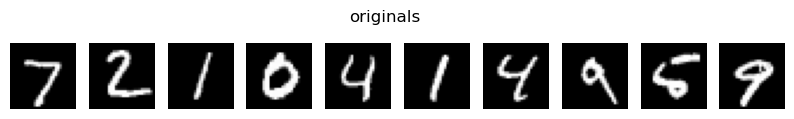

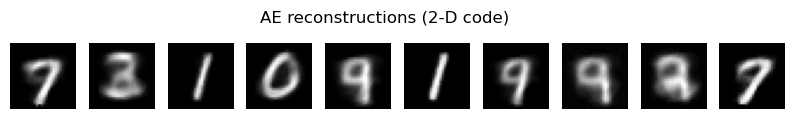

In [2]:
class AE(nn.Module):
    def __init__(self, z_dim=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, z_dim))
        self.dec = nn.Sequential(nn.Linear(z_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    def forward(self, x):
        z = self.enc(x.view(-1, 784))
        return self.dec(z), z

def train_ae(epochs=8):
    m = AE().to(DEVICE); opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epochs):
        tot = 0
        for x, _ in train_loader:
            x = x.to(DEVICE)
            recon, _ = m(x)
            loss = F.mse_loss(recon, x.view(-1, 784))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(x)
        print(f'AE epoch {ep+1}  recon MSE {tot/len(train_ds):.4f}')
    return m

ae = train_ae()
x, y = next(iter(test_loader)); x, y = x.to(DEVICE), y
with torch.no_grad(): recon, z_ae = ae(x)
show(x, title='originals'); show(recon, title='AE reconstructions (2-D code)')

### The latent space

Each test image becomes a point in 2-D. Colour = digit. Reconstruction works, but look at the gaps.

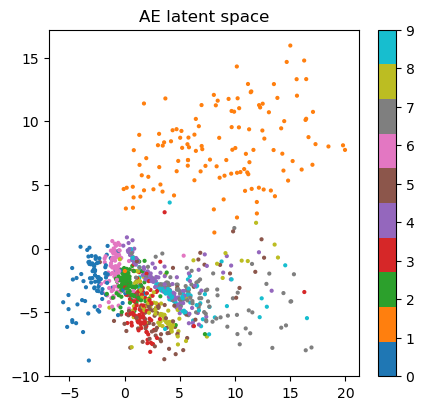

In [3]:
def scatter(z, y, title):
    z = z.detach().cpu()
    plt.figure(figsize=(5, 4.5)); s = plt.scatter(z[:, 0], z[:, 1], c=y, cmap='tab10', s=4)
    plt.colorbar(s); plt.title(title); plt.show()
scatter(z_ae, y, 'AE latent space')

### Why a plain AE can't generate

To generate, pick a random `z` and decode it. But nothing tells us *where* to sample: the AE's code has an arbitrary scale (here roughly -5 to 20) and an irregular shape, with clusters of different density and empty regions between them. A uniform draw over the bounding box mostly lands away from where the data lives, so samples skew toward a few digits and some are artifacts.

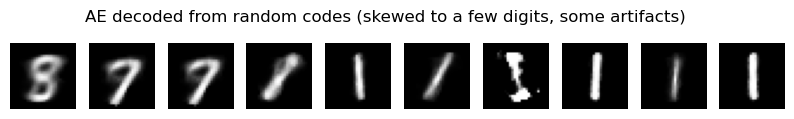

In [4]:
lo, hi = z_ae.min(0).values, z_ae.max(0).values
z_rand = (lo + (hi - lo) * torch.rand(10, 2, device=DEVICE))
with torch.no_grad(): samples = ae.dec(z_rand)
show(samples, title='AE decoded from random codes (skewed to a few digits, some artifacts)')

## 2. Variational Autoencoder

Two changes make the latent space usable:

**(a) Encode to a distribution, not a point.** The encoder outputs a mean `mu` and log-variance `logvar`; we *sample* `z ~ N(mu, sigma^2)`. Nearby codes must decode to similar images, which fills the gaps.

**(b) Regularize toward a standard normal prior `N(0, I)`.** Then at generation time we just sample `z ~ N(0, I)` and decode.

### Reparameterization trick
Sampling is not differentiable. Rewrite it so the randomness is an input:

$$z = \mu + \sigma \cdot \epsilon, \quad \epsilon \sim N(0, I)$$

Gradients now flow through `mu` and `sigma`; `epsilon` is just a constant noise input.

### Loss = reconstruction + KL (the negative ELBO)

$$\mathcal{L} = \underbrace{\text{BCE}(x, \hat{x})}_{\text{reconstruct well}} + \underbrace{D_{KL}\big(N(\mu,\sigma^2)\,\|\,N(0,I)\big)}_{\text{stay close to the prior}}$$

with the closed form $D_{KL} = -\tfrac12 \sum (1 + \log\sigma^2 - \mu^2 - \sigma^2)$.

The two terms pull against each other: reconstruction wants distinct, sharp codes; KL wants everything squashed to the same bubble.

In [5]:
class VAE(nn.Module):
    def __init__(self, z_dim=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(784, 256), nn.ReLU())
        self.mu, self.logvar = nn.Linear(256, z_dim), nn.Linear(256, z_dim)
        self.dec = nn.Sequential(nn.Linear(z_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.enc(x.view(-1, 784))
        return self.mu(h), self.logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)    # reparameterization
        return self.dec(z), mu, logvar

def vae_loss(recon, x, mu, logvar):
    bce = F.binary_cross_entropy(recon, x.view(-1, 784), reduction='sum')
    kl  = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return bce, kl

def train_vae(epochs=10):
    m = VAE().to(DEVICE); opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epochs):
        tb = tk = 0
        for x, _ in train_loader:
            x = x.to(DEVICE)
            recon, mu, logvar = m(x)
            bce, kl = vae_loss(recon, x, mu, logvar)
            loss = (bce + kl) / len(x)
            opt.zero_grad(); loss.backward(); opt.step(); tb += bce.item(); tk += kl.item()
        n = len(train_ds)
        print(f'VAE epoch {ep+1}  recon {tb/n:6.1f}  KL {tk/n:5.2f}  total {(tb+tk)/n:6.1f}')
    return m

vae = train_vae()

VAE epoch 1  recon  191.6  KL  6.69  total  198.3


VAE epoch 2  recon  166.3  KL  5.19  total  171.5


VAE epoch 3  recon  161.4  KL  5.17  total  166.6


VAE epoch 4  recon  159.0  KL  5.26  total  164.3


VAE epoch 5  recon  157.1  KL  5.33  total  162.4


VAE epoch 6  recon  155.5  KL  5.43  total  160.9


VAE epoch 7  recon  154.2  KL  5.51  total  159.7


VAE epoch 8  recon  153.1  KL  5.56  total  158.6


VAE epoch 9  recon  152.2  KL  5.62  total  157.8


VAE epoch 10  recon  151.3  KL  5.68  total  157.0


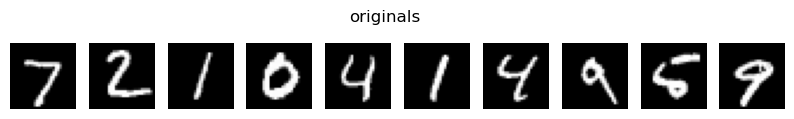

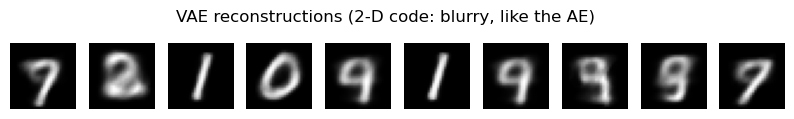

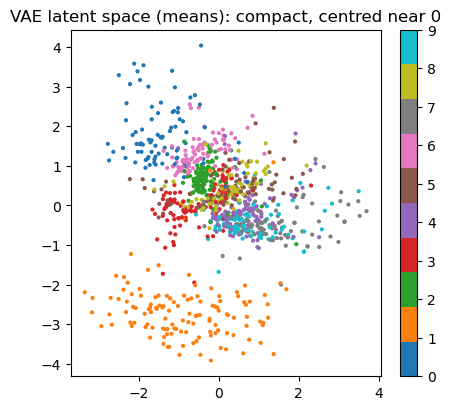

In [6]:
vae.eval()
with torch.no_grad():
    recon, mu, logvar = vae(x)
show(x, title='originals'); show(recon, title='VAE reconstructions (2-D code: blurry, like the AE)')
scatter(mu, y, 'VAE latent space (means): compact, centred near 0')

## 3. Generate

Sample `z ~ N(0, I)` and decode. This is what the KL term bought us.

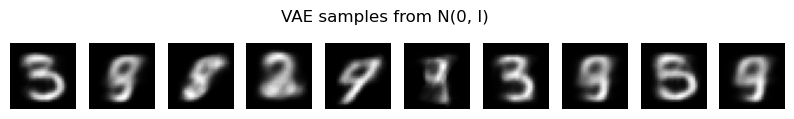

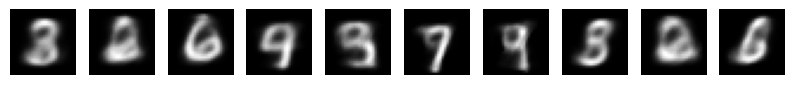

In [7]:
with torch.no_grad():
    samples = vae.dec(torch.randn(20, 2, device=DEVICE))
show(samples[:10], title='VAE samples from N(0, I)'); show(samples[10:], title='')

### Latent-space grid (only possible with a 2-D code)

Decode a regular grid of `z` values. Digits morph smoothly across the plane.

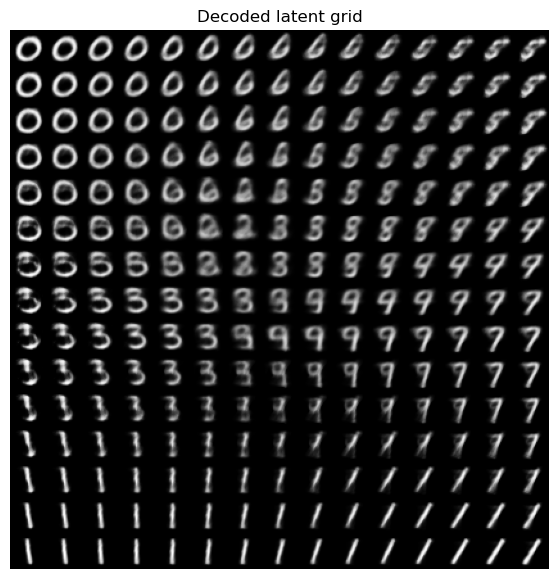

In [8]:
n = 15
zs = torch.linspace(-2.5, 2.5, n)
grid = torch.stack(torch.meshgrid(zs, zs.flip(0), indexing='xy'), -1).view(-1, 2).to(DEVICE)
with torch.no_grad(): imgs = vae.dec(grid).view(n, n, 28, 28).cpu()
canvas = imgs.permute(0, 2, 1, 3).reshape(n * 28, n * 28)
plt.figure(figsize=(7, 7)); plt.imshow(canvas, cmap='gray'); plt.axis('off'); plt.title('Decoded latent grid'); plt.show()

### Interpolation

Encode two real digits, walk in a straight line between their codes, decode each step.

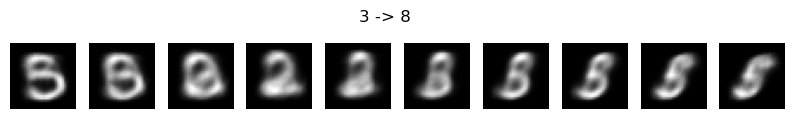

In [9]:
def interp(a, b, steps=10):
    with torch.no_grad():
        za, zb = vae.encode(x[a:a+1])[0], vae.encode(x[b:b+1])[0]
        ts = torch.linspace(0, 1, steps, device=DEVICE)[:, None]
        return vae.dec(za * (1 - ts) + zb * ts)

ia, ib = int((y == 3).nonzero()[0]), int((y == 8).nonzero()[0])
show(interp(ia, ib), title='3 -> 8')

## 4. Recap

| | Autoencoder | VAE |
|---|---|---|
| Encoder outputs | a point `z` | `mu`, `logvar` (a distribution) |
| Loss | reconstruction | reconstruction + KL |
| Latent space | irregular, has holes | smooth, centred on `N(0, I)` |
| Random-sample generation | unreliable | works |
| Reconstructions (2-D code) | blurry | blurry (similar) |

**The blur** has two causes here: a 2-D code simply cannot hold a whole digit, and the VAE decoder predicts the *average* of everything the noisy code might mean. A larger `z_dim` helps the first (exercise 1); the second is inherent to pixel-wise likelihood losses. GANs (next notebook) avoid it by replacing that loss with a learned critic.

## Exercises
1. Raise `z_dim` to 16. Reconstructions improve; can you still plot the latent space?
2. Multiply the KL term by `beta` (beta-VAE). What happens at `beta=0` (it becomes an AE) and `beta=10`?
3. Condition on the label: concat a one-hot digit to the encoder and decoder input (a conditional VAE) and generate a chosen digit.